In [1]:
# import the necessory packages
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import AveragePooling2D,Dropout,Flatten,Dense,Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array,load_img
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from imutils import paths
import matplotlib.pyplot as plt
import numpy as np
import argparse
import os

C:\Anaconda3\envs\aidl\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
# construct the argument parser and parse the arguments
ap=argparse.ArgumentParser()
ap.add_argument("-d","--dataset",type=str,default="dataset",help="path to input dataset")
ap.add_argument("-p","--plot",type=str,default="plot.png",help="path to output loss/accuracy plot")
ap.add_argument("-m","--model",type=str,default="mask_detector.h5",help="path to output face mask detector model")
args=vars(ap.parse_args(args=[]))

In [3]:
# initialize the initial learning rate, number of epochs to train for and batch size
INIT_LR=1e-4
EPOCHS=20
BS=16

In [4]:
# grab the list of images in our datase directory, then initialize the list of data (i.e., images) and class images
print("[INFO] loading images...")
imagePaths=list(paths.list_images(args["dataset"]))
data=[]
labels=[]

[INFO] loading images...


In [5]:
# loop over the image paths
for imagePath in imagePaths:
    # extract the class label from the filename
    label=imagePath.split(os.path.sep)[-2]

    # load the input image (224x224) and preprocess it
    image=load_img(imagePath,target_size=(224,224))
    image=img_to_array(image)
    image=preprocess_input(image)

    # update the data and labels lists respectively
    data.append(image)
    labels.append(label)

C:\Anaconda3\envs\aidl\Lib\site-packages\PIL\Image.py:1045: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [6]:
# convert the data and labels to numpy arrays
data=np.array(data,dtype="float32")
labels=np.array(labels)

In [7]:
# perform one-hot encoding on the labels
lb=LabelBinarizer()
labels=lb.fit_transform(labels)
labels=to_categorical(labels)

In [8]:
# partition the data into training and testing splits using 75% of the data for training and the remaining 25% for testing
(trainX,testX,trainY,testY)=train_test_split(data,labels,test_size=0.20,stratify=labels,random_state=42)

In [9]:
# construct the training image generator for data augmentation
aug=ImageDataGenerator(rotation_range=20,
                       zoom_range=0.15,
                       width_shift_range=0.2,
                       height_shift_range=0.2,
                       shear_range=0.15,
                       horizontal_flip=True,
                       fill_mode="nearest")

In [10]:
# load the MobileNetV2 network, ensuring the head FC layer sets are left off
baseModel=MobileNetV2(weights="imagenet",include_top=False,
                      input_tensor=Input(shape=(224,224,3)))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24196\677997183.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  baseModel=MobileNetV2(weights="imagenet",include_top=False,


In [11]:
# construct the head of the model that will be placed on top of the base model
headModel=baseModel.output
headModel=AveragePooling2D(pool_size=(7,7))(headModel)
headModel=Flatten(name="flatten")(headModel)
headModel=Dense(128,activation="relu")(headModel)
headModel=Dropout(0.5)(headModel)
headModel=Dense(2,activation="softmax")(headModel)

In [12]:
# place the head FC model on top of the base model (this will become the actual model we will train)
model=Model(inputs=baseModel.input,outputs=headModel)

In [13]:
# loop over all layers in the base model and freeze them so they will *not* be updated 
# during the first training process
for layer in baseModel.layers:
    layer.trainable=False

In [14]:
# compile our model
print("[INFO] compiling model...")
opt=Adam(learning_rate=INIT_LR)
model.compile(loss="binary_crossentropy",optimizer=opt,metrics=["accuracy"])

[INFO] compiling model...


In [15]:
# train the head of the network
print("[INFO] training head...")
H=model.fit(aug.flow(trainX,trainY,batch_size=BS),
            steps_per_epoch=int(np.ceil(len(trainX)/BS)),
            validation_data=(testX,testY),
            epochs=EPOCHS)

[INFO] training head...
Epoch 1/20
193/193 ━━━━━━━━━━━━━━━━━━━━ 175s 855ms/step - accuracy: 0.9070 - loss: 0.2909 - val_accuracy: 0.9870 - val_loss: 0.0947
Epoch 2/20
193/193 ━━━━━━━━━━━━━━━━━━━━ 164s 851ms/step - accuracy: 0.9698 - loss: 0.1080 - val_accuracy: 0.9896 - val_loss: 0.0603
Epoch 3/20
193/193 ━━━━━━━━━━━━━━━━━━━━ 180s 934ms/step - accuracy: 0.9779 - loss: 0.0756 - val_accuracy: 0.9883 - val_loss: 0.0527
Epoch 4/20
193/193 ━━━━━━━━━━━━━━━━━━━━ 208s 965ms/step - accuracy: 0.9831 - loss: 0.0580 - val_accuracy: 0.9922 - val_loss: 0.0436
Epoch 5/20
193/193 ━━━━━━━━━━━━━━━━━━━━ 196s 1s/step - accuracy: 0.9847 - loss: 0.0545 - val_accuracy: 0.9909 - val_loss: 0.0388
Epoch 6/20
193/193 ━━━━━━━━━━━━━━━━━━━━ 159s 823ms/step - accuracy: 0.9860 - loss: 0.0444 - val_accuracy: 0.9909 - val_loss: 0.0367
Epoch 7/20
193/193 ━━━━━━━━━━━━━━━━━━━━ 157s 815ms/step - accuracy: 0.9844 - loss: 0.0478 - val_accuracy: 0.9922 - val_loss: 0.0361
Epoch 8/20
193/193 ━━━━━━━━━━━━━━━━━━━━ 154s 797ms/step

In [16]:
# Make predictions on the testing set
print("[INFO] evaluating network...")
predIDxs=model.predict(testX,batch_size=BS)

[INFO] evaluating network...
49/49 ━━━━━━━━━━━━━━━━━━━━ 39s 731ms/step


In [17]:
# For each image in the testing set we need to find the index of the label with corresponding largest predicted probability
predIDxs=np.argmax(predIDxs,axis=1)

In [18]:
# show a nicely formatted classification report
print(classification_report(testY.argmax(axis=1),predIDxs,target_names=lb.classes_))

              precision    recall  f1-score   support

   with_mask       0.99      1.00      0.99       384
without_mask       1.00      0.99      0.99       386

    accuracy                           0.99       770
   macro avg       0.99      0.99      0.99       770
weighted avg       0.99      0.99      0.99       770



In [19]:
# serialize the model to disk
print("[INFO] saving mask detector model...")
model.save(args["model"])

[INFO] saving mask detector model...


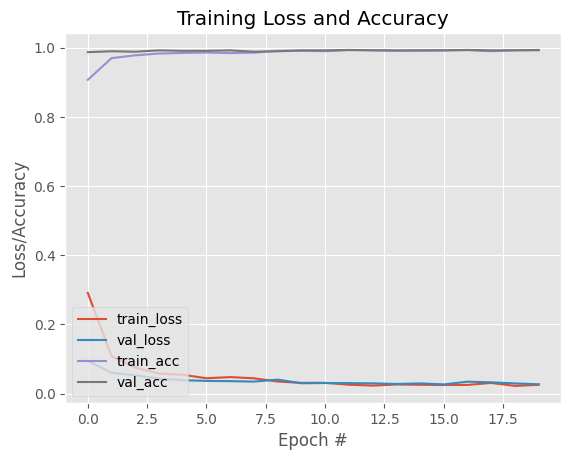

In [20]:
# plot the training loss and accuracy 
N=EPOCHS
plt.style.use("ggplot")
plt.figure()
plt.plot(np.arange(0,N),H.history["loss"],label="train_loss")
plt.plot(np.arange(0,N),H.history["val_loss"],label="val_loss")
plt.plot(np.arange(0,N),H.history["accuracy"],label="train_acc")
plt.plot(np.arange(0,N),H.history["val_accuracy"],label="val_acc")
plt.title("Training Loss and Accuracy")
plt.xlabel("Epoch #")
plt.ylabel("Loss/Accuracy")
plt.legend(loc="lower left")
plt.savefig(args["plot"])